# 06 · The model

Notebook 05 showed that no blanket rule works: waiting pays on some trips
and backfires on others. Here I build a model that decides **trip by trip,
day by day**.

**Key takeaways**
1. The model estimates the **probability the fare drops at least 5% in the
   coming days**. Each day I wait while that probability is above a cutoff,
   and buy otherwise. The cutoff is an expected-value rule.
2. Tested walk-forward, LightGBM **saves 3–5% per trip ($5–12) when starting
   30–60 days out**, and beats "buy now" from every starting point. It loses
   money on only 1–12% of trips.
3. It captures about **a quarter to a third of the hindsight ceiling** when
   starting 30–45 days out.
4. LightGBM does roughly **twice as well as logistic regression**, so the
   nonlinear interactions matter.
5. The biggest drivers are **how today's fare compares with the route's
   usual level**, **days to departure** and **how far today's fare is above
   the cheapest seen so far**.
6. The probabilities run low early in the season, and the cutoff tuned on
   recent data absorbs that. Two leaks I found and closed along the way:
   labels cut off by the end of data collection, and choosing settings on
   the test months.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from sklearn.metrics import brier_score_loss, roc_auc_score

from flight_pricing.backtest import START_DAYS, hindsight_best, load_fare_matrix
from flight_pricing.data import connect
from flight_pricing.features import FEATURES, build_features
from flight_pricing.model import fit_lgb, fit_logit, policy_pct_by_fold, predict, walk_forward
from flight_pricing.plotting import SERIES, TEXT_MUTED, use_style

use_style()
con = connect()
trips, F = load_fare_matrix(con, full_window_only=False)
TEST_MONTHS = pd.period_range("2022-06", "2022-09", freq="M")

## What the model predicts

Every trip on every day from 60 to 2 days out is one **decision point**.
For each one, the model estimates

$$p = P\big(\text{fare drops at least 5\% within the next } h \text{ days}\big)$$

The **label** for training is whether that actually happened. It's the only
column that looks at the future, and it's only used for trips that have
already departed.

I try three windows, $h \in \{7, 14, 21\}$ days. A short window can't see a
slow decline from 60 days out, and a long one can wander into the late
price spike. Which one to use is chosen inside the walk-forward (below),
never by peeking at the test months.

In [2]:
dfs = {h: build_features(con, horizon=h) for h in (7, 14, 21)}
df7 = dfs[7]
print(f"{len(df7):,} decision points")
df7.groupby(pd.cut(df7.days_ahead, [1, 7, 14, 21, 30, 45, 60])).drop_ahead.mean().rename(
    "share with a 5% drop in the next 7 days").round(3).to_frame()

1,947,628 decision points


,share with a 5% drop in the next 7 days
days_ahead,
"(1, 7]",0.22
"(7, 14]",0.406
"(14, 21]",0.446
"(21, 30]",0.461
"(30, 45]",0.428
"(45, 60]",0.435


About 40% of decision points see a 5%+ drop within a week, except in the
final week, when fares mostly go up.

**One leak I had to close:** data collection stopped on October 5. For a
decision on October 1, the next 7 days are only partly collected, and a
drop after October 5 would look like "no drop". This is called
**right-censoring**, and it made late-season drop rates look artificially
low. Those labels are marked unknown and excluded.

## The inputs

Everything is known on the decision day:

| Input | Why it might matter |
|---|---|
| `days_ahead`, `days_to_deadline` | Fares climb near departure, in steps at 21/14/7 days (notebooks 02, 05) |
| `log_vs_route` | Today's fare vs. the route's usual fare. High fares tend to come down (notebook 05). The route's usual fare is computed from **training trips only**. |
| `log_vs_min_so_far`, `log_vs_max_so_far` | Where today sits in the range I've seen for this trip |
| `log_change_prev`, `log_change_week` | Recent moves: did it just jump or just drop? |
| `n_options`, `seatsRemaining`, `isNonStop`, `isBasicEconomy`, `ulcc` | What's on offer, and how scarce it is |
| `flight_dow`, `search_dow` | Day-of-week patterns |
| `origin`, `dest` | Route-specific behavior (LightGBM only) |

## From probability to decision: the expected-value rule

Suppose waiting has two outcomes: the fare drops and I save about $G$ (as a
fraction of the fare), or it doesn't and I lose about $L$. Waiting is worth
it when the expected gain beats the expected loss:

$$p \cdot G > (1 - p) \cdot L \quad\Longleftrightarrow\quad p > \frac{L}{G + L} = \theta$$

So the expected-value rule is just **"wait while $p > \theta$"**. Rather
than estimating $G$ and $L$ separately, I tune $\theta$ directly to
maximize % saved on recent departed trips. A tuned $\theta = 0.5$ means
gains and losses are about the same size. A higher $\theta$ means losses
are bigger, so I need more confidence before waiting.

## Walk-forward training

For each test month (by decision date), June to September:

1. **Validation:** trips that departed in the 4 weeks before the month.
   For each window $h$, fit the model on trips that departed *before* that,
   and pick the $h$ and $\theta$ that save the most on the validation trips.
2. **Refit** the chosen model on every trip that departed before the month.
3. **Test:** apply it, with that $\theta$, to every decision made during
   the month.

The test month is never used to choose anything.

In [3]:
P_lgb, folds_lgb = walk_forward(dfs, trips, F, TEST_MONTHS, fit=fit_lgb)
P_logit, folds_logit = walk_forward(dfs, trips, F, TEST_MONTHS, fit=fit_logit)
folds_lgb[["test_month", "horizon", "theta", "val_pct_saved", "train_rows", "test_rows"]].round(3)

,test_month,horizon,theta,val_pct_saved,train_rows,test_rows
0,2022-06,14,0.7,0.058,207073,358862
1,2022-07,21,0.5,0.109,515374,422756
2,2022-08,21,0.5,0.104,861970,320080
3,2022-09,21,0.4,0.070,1270199,310077


The 21-day window wins from July on (June picked 14), so a longer view
helps. The cutoff
moves between 0.4 and 0.65 as the season changes.

## Results

Each policy is scored on the decisions made in the test months. For
reference, the honest simple rule from notebook 05 (walk-forward N) was
"buy now" in every month, which saves 0%.

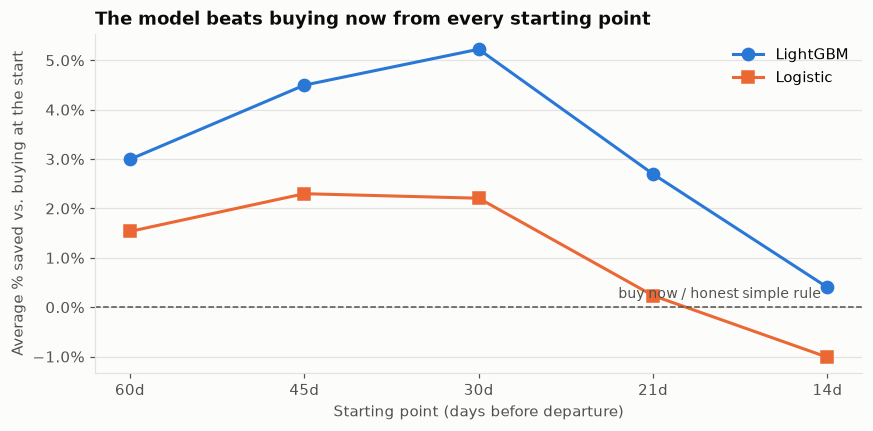

,start,model,trips,avg_saved_pct,total_saved_pct,avg_saved_usd,share_lost_money,share_of_ceiling
0,60d,LightGBM,10361,0.030,0.034,4.757,0.010,0.099
1,60d,Logistic,10361,0.015,0.018,2.542,0.012,0.051
2,45d,LightGBM,17311,0.045,0.064,8.797,0.027,0.195
3,45d,Logistic,17311,0.023,0.030,4.098,0.036,0.100
4,30d,LightGBM,21315,0.052,0.086,12.040,0.073,0.290
5,30d,Logistic,21315,0.022,0.036,5.064,0.075,0.123
6,21d,LightGBM,24558,0.027,0.057,8.124,0.109,0.199
7,21d,Logistic,24558,0.002,0.014,2.042,0.056,0.017
8,14d,LightGBM,26044,0.004,0.021,3.090,0.115,0.048
9,14d,Logistic,26044,-0.010,-0.005,-0.792,0.044,-0.122


In [4]:
rows = []
for s in START_DAYS:
    for name, P, folds in [("LightGBM", P_lgb, folds_lgb), ("Logistic", P_logit, folds_logit)]:
        idx, pct = policy_pct_by_fold(F, P, trips, folds, s, TEST_MONTHS)
        p0 = F[idx, s]
        ceiling = np.nanmean((p0 - hindsight_best(F[idx], s)) / p0)
        rows.append({"start": f"{s}d", "model": name, "trips": len(idx),
                     "avg_saved_pct": np.nanmean(pct), "total_saved_pct": np.nansum(pct * p0) / p0.sum(),
                     "avg_saved_usd": np.nanmean(pct * p0), "share_lost_money": np.mean(pct < 0),
                     "share_of_ceiling": np.nanmean(pct) / ceiling})
results = pd.DataFrame(rows)

fig, ax = plt.subplots()
for (name, g), color, marker in zip(results.groupby("model", sort=False), SERIES, ["o", "s"]):
    ax.plot(g.start, g.avg_saved_pct, color=color, marker=marker, markersize=8, label=name)
ax.axhline(0, color=TEXT_MUTED, linewidth=1, linestyle="--")
ax.annotate("buy now / honest simple rule", (4, 0), xytext=(-4, 6), textcoords="offset points",
            ha="right", color=TEXT_MUTED, fontsize=9)
ax.set_title("The model beats buying now from every starting point")
ax.set_xlabel("Starting point (days before departure)")
ax.set_ylabel("Average % saved vs. buying at the start")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.legend(loc="upper right")
plt.show()

results.round(3)

- **Starting 30–45 days out is the sweet spot:** about 5% saved per trip
  ($9–12), and 6–9% of total spend, losing money on only 3–7% of trips.
- **The total % is higher than the average %**, the same pattern as
  notebook 05: the model saves more on expensive tickets.
- **From 14 days out there's little left to win** (the ceiling is only
  ~8%), and the model roughly breaks even.
- **From 60 days out**, a fixed "buy 21 days out" rule looked better
  (about 10%) in notebook 05, but only when N was picked with hindsight.
  The honest walk-forward version never chose it. A model that plans over
  the whole 60 days, rather than looking a few weeks ahead, should close this
  gap. That's the job of the dynamic programming solver in notebook 07.
- **These numbers are sensitive.** Before I made the runs reproducible
  (fixing the row order LightGBM samples from), re-running this same notebook
  moved the 60-day result anywhere from about 3% to 5%. Results that shift
  this much need error bars, which notebook 09 adds with the bootstrap.
- **LightGBM vs. logistic:** logistic regression can only add up effects
  linearly. LightGBM can learn interactions like "a high fare matters more
  when a deadline is far away", and that roughly doubles the savings.

## Are the probabilities trustworthy? (calibration)

The policy uses $p$ directly, so I check whether "60% chance of a drop"
really means a drop about 60% of the time. I group test predictions into
ten bins and compare the average prediction with how often a drop actually
happened.

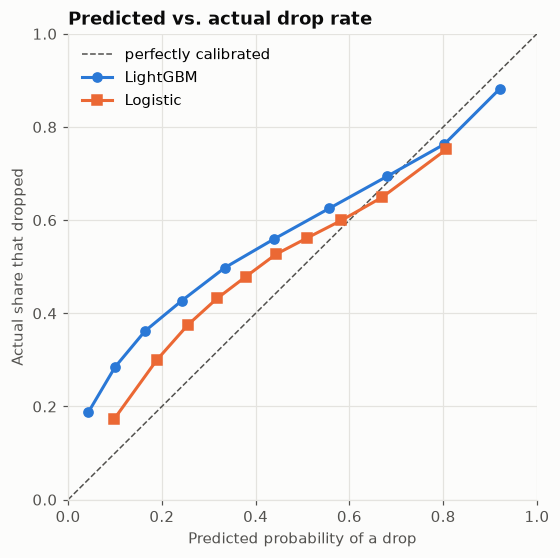

AUC  Brier  Brier, constant guess  mean predicted  \
model    month                                                          
LightGBM 2022-06  0.778  0.195                  0.241           0.526   
         2022-07  0.692  0.266                  0.240           0.426   
         2022-08  0.745  0.218                  0.247           0.334   
         2022-09  0.774  0.188                  0.237           0.410   
Logistic 2022-06  0.718  0.216                  0.250           0.434   
         2022-07  0.652  0.250                  0.247           0.438   
         2022-08  0.687  0.229                  0.247           0.398   
         2022-09  0.721  0.208                  0.237           0.426   

                  actual rate  
model    month                 
LightGBM 2022-06        0.596  
         2022-07        0.598  
         2022-08        0.444  
         2022-09        0.388  
Logistic 2022-06        0.486  
         2022-07        0.559  
         2022-08        0.444  
         2022-09        0.388

In [5]:
def test_predictions(folds, fit_name):
    out = []
    for f in folds.itertuples():
        d = f.test_data
        d = d[d.drop_ahead.notna()]
        out.append(pd.DataFrame({"p": predict(f.model, d), "y": d.drop_ahead.astype(int),
                                 "month": f.test_month, "model": fit_name}))
    return pd.concat(out)

preds = pd.concat([test_predictions(folds_lgb, "LightGBM"), test_predictions(folds_logit, "Logistic")])

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], color=TEXT_MUTED, linewidth=1, linestyle="--", label="perfectly calibrated")
for (name, g), color, marker in zip(preds.groupby("model", sort=False), SERIES, ["o", "s"]):
    bins = pd.qcut(g.p, 10, duplicates="drop")
    cal = g.groupby(bins, observed=True).agg(p=("p", "mean"), y=("y", "mean"))
    ax.plot(cal.p, cal.y, color=color, marker=marker, label=name)
ax.set_title("Predicted vs. actual drop rate")
ax.set_xlabel("Predicted probability of a drop")
ax.set_ylabel("Actual share that dropped")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.grid(axis="x")
ax.legend(loc="upper left")
plt.show()

summary = preds.groupby(["model", "month"]).apply(lambda g: pd.Series({
    "AUC": roc_auc_score(g.y, g.p),
    "Brier": brier_score_loss(g.y, g.p),
    "Brier, constant guess": brier_score_loss(g.y, np.full(len(g), g.y.mean())),
    "mean predicted": g.p.mean(), "actual rate": g.y.mean()}), include_groups=False)
summary.round(3)

**How to read this:**

- **AUC** (0.5 = coin flip, 1 = perfect) measures whether the model *ranks*
  decisions correctly. LightGBM's 0.69–0.78 is solid for a noisy problem like
  this, and it beats logistic regression in every month.
- **Brier score** is the mean squared error of the probabilities,
  $\frac{1}{n}\sum (p_i - y_i)^2$. Lower is better. The "constant guess"
  column is a tough benchmark, because it uses the *actual* drop rate of the
  test month, which nobody knows in advance.
- **The curve sits above the diagonal for low predictions.** When the model
  says 5%, drops actually happen about 19% of the time, so it's
  overconfident that the fare *won't* drop.
- **The predictions run low in June–August** (for example, 0.34 predicted
  vs. 0.44 actual in August). The training data came mostly from earlier
  trips, when drops were less common. LightGBM's Brier score beats the
  constant guess in every month except July. The ranking is still good, and since $\theta$ is tuned on the most
  recent trips, the policy adjusts for the shift. A cleaner fix is to
  **recalibrate** the probabilities on recent data, which is on the list of
  extras.

## What drives the decisions (SHAP)

SHAP splits each prediction into contributions from each input, so I can
see *why* the model says wait. The chart shows the average size of each
input's contribution in the September model.

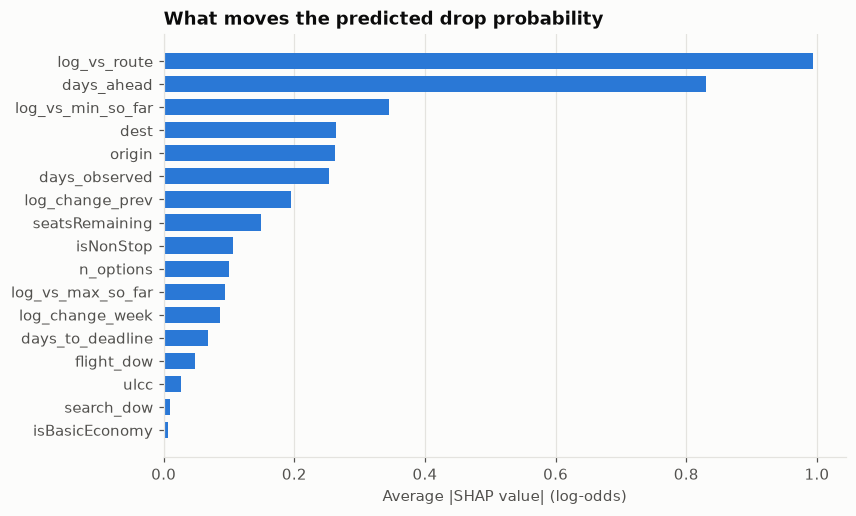

In [6]:
last = folds_lgb.iloc[-1]
sample = last.test_data.sample(20000, random_state=0)
contrib = last.model.predict(sample[FEATURES], pred_contrib=True)[:, :-1]  # last column = baseline
importance = pd.Series(np.abs(contrib).mean(axis=0), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.values, color=SERIES[0], height=0.7)
ax.set_title("What moves the predicted drop probability")
ax.set_xlabel("Average |SHAP value| (log-odds)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
plt.show()

The top inputs match what the earlier notebooks found:

- **`log_vs_route`**: an unusually high fare for this route is likely to
  come down, and an unusually low one isn't.
- **`days_ahead`**: where I am relative to departure. The trees can split
  it right at 21, 14 and 7 days, so it carries the deadline effect itself,
  and the separate `days_to_deadline` input adds little.
- **`log_vs_min_so_far`**: if today's fare is well above the cheapest I've
  seen for this trip, a drop back is more likely.
- **The route itself** (`origin`, `dest`): routes behave differently.

Day of week barely matters, which is already a hint about the "book on a
Tuesday" myth that notebook 03 will test properly.

## Next

- **Notebook 09** puts confidence intervals on these savings (bootstrap by
  route) and tests whether the model beats the simple rules, compared on the
  same trips.
- **Notebook 07** solves the problem with dynamic programming, which plans
  over the whole remaining window and should do better from 60 days out.